# Pipeline Gardenia | Etapa 5: OLAP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anlbp/Projeto-Gardenia-unifeob/blob/main/recursos/dados/notebook_dados_nao_filtrados/05_olap.ipynb)

**Lê:** `dw_gardenia_N.sqlite`, gerado pelo notebook 04 (por padrão em `{DRIVE_PASTA}/dw`).
**Gera:** tabelas de resultado das análises em CSV, por padrão em `{DRIVE_PASTA}/olap`.

> Antes de rodar este notebook, rode o 03 e o 04.

## O que é OLAP

OLAP (*Online Analytical Processing*) é olhar a mesma medida (aqui, o valor das vendas) por diferentes ângulos e níveis de detalhe. As quatro operações clássicas:

| Operação | O que faz | Exemplo neste notebook |
|---|---|---|
| **Roll-up** | sobe de nível, resumindo | mês → trimestre → ano |
| **Drill-down** | desce de nível, detalhando | categoria → produto |
| **Slice** | fixa **uma** dimensão em um valor | só o mês de maior venda |
| **Dice** | filtra **várias** dimensões ao mesmo tempo | vendas concluídas, no 1º semestre, nas 3 maiores categorias |

Além delas, a seção 6 faz um **pivot** (cruzamento de duas dimensões) e a seção 7 calcula a **taxa de cancelamento**.

**Medida usada:** `valor_liquido` (`valor_total - desconto`), somado sobre **todas** as compras, inclusive as canceladas, quando o texto não disser o contrário. A seção 7 mostra o peso dos cancelamentos.

## 1. Configuração e carga

In [1]:
# ============================ CONFIGURAÇÃO ============================
FONTE_DW = "drive"          # "drive" | "github" | "upload" | "local"
LOTE = "1"                  # mesmo lote usado nos notebooks 03 e 04

DRIVE_PASTA = "/content/drive/MyDrive/gardenia"   # o 04 grava em {DRIVE_PASTA}/dw

# --- usado quando FONTE_DW == "github" (o .sqlite versionado no repositório) ---
GITHUB_USUARIO = "Anlbp"
GITHUB_REPO    = "Projeto-Gardenia-unifeob"
GITHUB_BRANCH  = "main"
PASTA_GITHUB   = "recursos/dados/dw"

# --- usado quando FONTE_DW == "local" ---
PASTA_LOCAL = "dw"

# --- saída ---
SALVAR_NO_DRIVE = True      # True: grava em {DRIVE_PASTA}/olap
SAIDA = "olap"              # pasta usada quando SALVAR_NO_DRIVE = False
# =======================================================================

In [2]:
import os
import shutil
import sqlite3
import urllib.error
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.options.display.float_format = "{:,.2f}".format

nome_db = f"dw_gardenia_{LOTE}.sqlite"
LOCAL_DB = "dw_trabalho.sqlite"   # cópia local: abrir o SQLite direto no Drive é lento

try:
    if FONTE_DW == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        shutil.copy(f"{DRIVE_PASTA}/dw/{nome_db}", LOCAL_DB)

    elif FONTE_DW == "github":
        branch = GITHUB_BRANCH.removeprefix("tree/")
        url = f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{GITHUB_REPO}/{branch}/{PASTA_GITHUB}/{nome_db}"
        print("baixando", url)
        urllib.request.urlretrieve(url, LOCAL_DB)

    elif FONTE_DW == "upload":
        from google.colab import files
        print(f"Selecione o arquivo {nome_db} gerado pelo notebook 04")
        files.upload()
        shutil.copy(nome_db, LOCAL_DB)

    elif FONTE_DW == "local":
        shutil.copy(f"{PASTA_LOCAL}/{nome_db}", LOCAL_DB)

    else:
        raise ValueError('FONTE_DW deve ser "drive", "github", "upload" ou "local".')

except (FileNotFoundError, urllib.error.HTTPError):
    raise FileNotFoundError(
        f"Não encontrei o DW ({nome_db}).\n"
        "Rode antes os notebooks 03 e 04 com o mesmo LOTE. "
        "Se o arquivo está em outro lugar, ajuste FONTE_DW e as pastas na configuração."
    ) from None

con = sqlite3.connect(LOCAL_DB)
tabelas = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")]
print("Tabelas no DW:", tabelas)
for t in tabelas:
    n = con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    print(f"  {t:12s} {n:>6} linhas")

Mounted at /content/drive
Tabelas no DW: ['dim_cliente', 'dim_data', 'dim_produto', 'fato_vendas']
  dim_cliente    5000 linhas
  dim_data        366 linhas
  dim_produto    2305 linhas
  fato_vendas    1184 linhas


## 2. O cubo de análise

Uma única consulta SQL junta a fato com as três dimensões. O resultado é uma tabela larga, o "cubo", sobre a qual as operações OLAP viram `groupby` e filtros.

In [3]:
consulta = '''
SELECT f.id_compra, f.status, f.quantidade, f.valor_total, f.desconto, f.valor_liquido, f.satisfacao,
       d.data, d.ano, d.trimestre, d.mes, d.nome_mes, d.ano_mes, d.dia_semana,
       p.id_produto, p.nome AS produto, p.categoria, p.faixa_preco,
       c.id_cliente, c.faixa_etaria
FROM fato_vendas f
JOIN dim_data    d ON d.id_data    = f.id_data
JOIN dim_produto p ON p.id_produto = f.id_produto
JOIN dim_cliente c ON c.id_cliente = f.id_cliente
'''
cubo = pd.read_sql(consulta, con, parse_dates=["data"])
con.close()

n_fato = len(cubo)
assert n_fato > 0, "o cubo está vazio"
print(f"Cubo: {cubo.shape[0]} compras x {cubo.shape[1]} colunas")
print(f"Período: {cubo['data'].min().date()} a {cubo['data'].max().date()}")
print(f"Valor líquido total: R$ {cubo['valor_liquido'].sum():,.2f}")
cubo.head()

Cubo: 1184 compras x 20 colunas
Período: 2025-10-09 a 2026-10-09
Valor líquido total: R$ 2,506,077.80


,id_compra,status,quantidade,valor_total,desconto,valor_liquido,satisfacao,data,ano,trimestre,mes,nome_mes,ano_mes,dia_semana,id_produto,produto,categoria,faixa_preco,id_cliente,faixa_etaria
0,1_15,entregue,8,"3,475.74",448.70,"3,027.04",2.00,2026-09-09,2026,3,9,setembro,2026-09,quarta,1_3038,Feijão Plus,Roupas,Até R$ 100,1_4487,45-54
1,1_16,cancelado,8,474.91,33.96,440.95,1.00,2026-05-23,2026,2,5,maio,2026-05,sábado,1_992,TV Max,Livros,Acima de R$ 600,1_3240,25-34
2,1_21,enviado,9,"3,699.06",973.60,"2,725.46",4.00,2026-05-29,2026,2,5,maio,2026-05,sexta,1_1409,Mesa Basic,Eletrônicos,R$ 300 a 600,1_2478,45-54
3,1_26,pendente,4,"2,455.84",561.57,"1,894.27",NaN,2026-08-06,2026,3,8,agosto,2026-08,quinta,1_1603,Romance Plus,Esportes,Até R$ 100,1_3167,45-54
4,1_28,enviado,1,"4,140.57",411.00,"3,729.57",3.00,2026-02-13,2026,1,2,fevereiro,2026-02,sexta,1_4856,Feijão Max,Casa,R$ 100 a 300,1_2381,35-44


## 3. Roll-up: do mês ao ano

Subir de nível: o mesmo valor, agora resumido em períodos cada vez maiores.

Nível mês:


ano_mes,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
valor_liquido,"172,560.22","233,332.88","208,232.17","176,518.97","154,155.07","233,310.87","207,756.84","200,754.35","203,306.99","267,439.28","174,181.47","221,789.86","52,738.83"


Nível trimestre:


,2025-T4,2026-T1,2026-T2,2026-T3,2026-T4
valor_liquido,"614,125.27","563,984.91","611,818.18","663,410.61","52,738.83"


Nível ano:


ano,2025,2026
valor_liquido,"614,125.27","1,891,952.53"


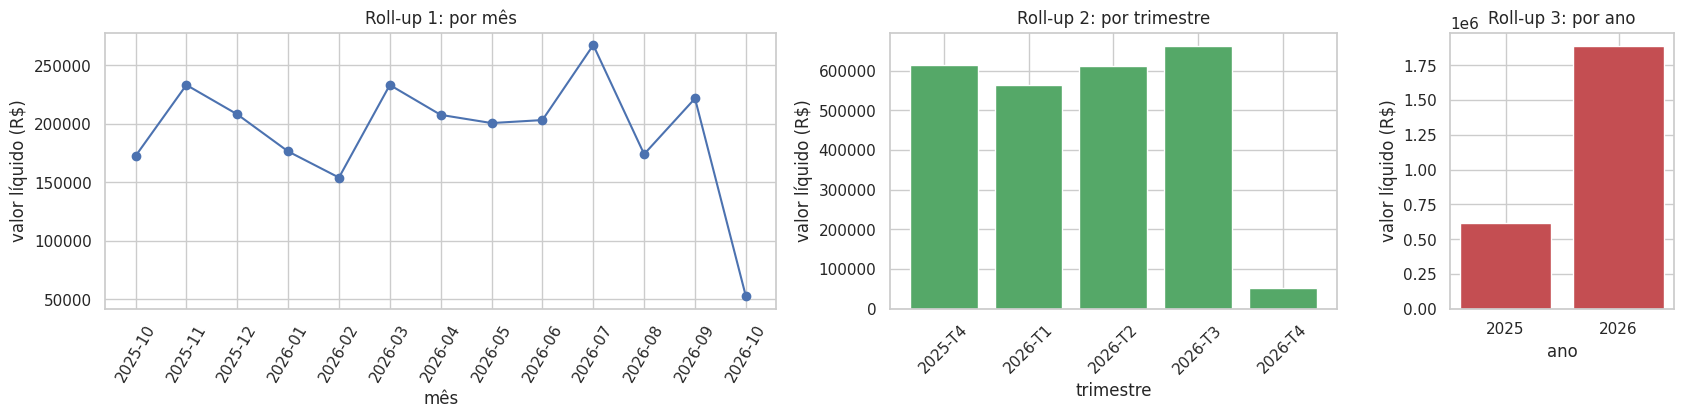

Mês de maior venda: 2026-07 (R$ 267,439.28). Mês mais fraco: 2026-10 (R$ 52,738.83).
Atenção: o primeiro mês (2025-10) está incompleto, os dados começam em 09/10/2025. Os totais do primeiro trimestre e do primeiro ano também ficam menores por isso.
Atenção: o último mês (2026-10) está incompleto, os dados vão só até 09/10/2026. A queda no fim da curva e o total do último trimestre são efeito disso.


In [4]:
por_mes = cubo.groupby("ano_mes")["valor_liquido"].sum()
por_trimestre = cubo.groupby(["ano", "trimestre"])["valor_liquido"].sum()
por_trimestre.index = [f"{a}-T{t}" for a, t in por_trimestre.index]
por_ano = cubo.groupby("ano")["valor_liquido"].sum()

print("Nível mês:");      display(por_mes.to_frame("valor_liquido").T)
print("Nível trimestre:"); display(por_trimestre.to_frame("valor_liquido").T)
print("Nível ano:");      display(por_ano.to_frame("valor_liquido").T)

fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [3, 2, 1]})
eixos[0].plot(por_mes.index, por_mes.values, marker="o", color="#4C72B0")
eixos[0].set(title="Roll-up 1: por mês", xlabel="mês", ylabel="valor líquido (R$)")
eixos[0].tick_params(axis="x", rotation=60)
eixos[1].bar(por_trimestre.index, por_trimestre.values, color="#55A868")
eixos[1].set(title="Roll-up 2: por trimestre", xlabel="trimestre", ylabel="valor líquido (R$)")
eixos[1].tick_params(axis="x", rotation=45)
eixos[2].bar(por_ano.index.astype(str), por_ano.values, color="#C44E52")
eixos[2].set(title="Roll-up 3: por ano", xlabel="ano", ylabel="valor líquido (R$)")
plt.tight_layout()
plt.show()

primeiro, ultimo = cubo["data"].min(), cubo["data"].max()
print(f"Mês de maior venda: {por_mes.idxmax()} (R$ {por_mes.max():,.2f}). Mês mais fraco: {por_mes.idxmin()} (R$ {por_mes.min():,.2f}).")
if primeiro.day > 3:
    print(f"Atenção: o primeiro mês ({primeiro:%Y-%m}) está incompleto, os dados começam em {primeiro:%d/%m/%Y}. "
          "Os totais do primeiro trimestre e do primeiro ano também ficam menores por isso.")
if ultimo.day < 28:
    print(f"Atenção: o último mês ({ultimo:%Y-%m}) está incompleto, os dados vão só até {ultimo:%d/%m/%Y}. "
          "A queda no fim da curva e o total do último trimestre são efeito disso.")

## 4. Drill-down: da categoria ao produto

Descer de nível: de uma visão geral para o detalhe de onde ela vem.

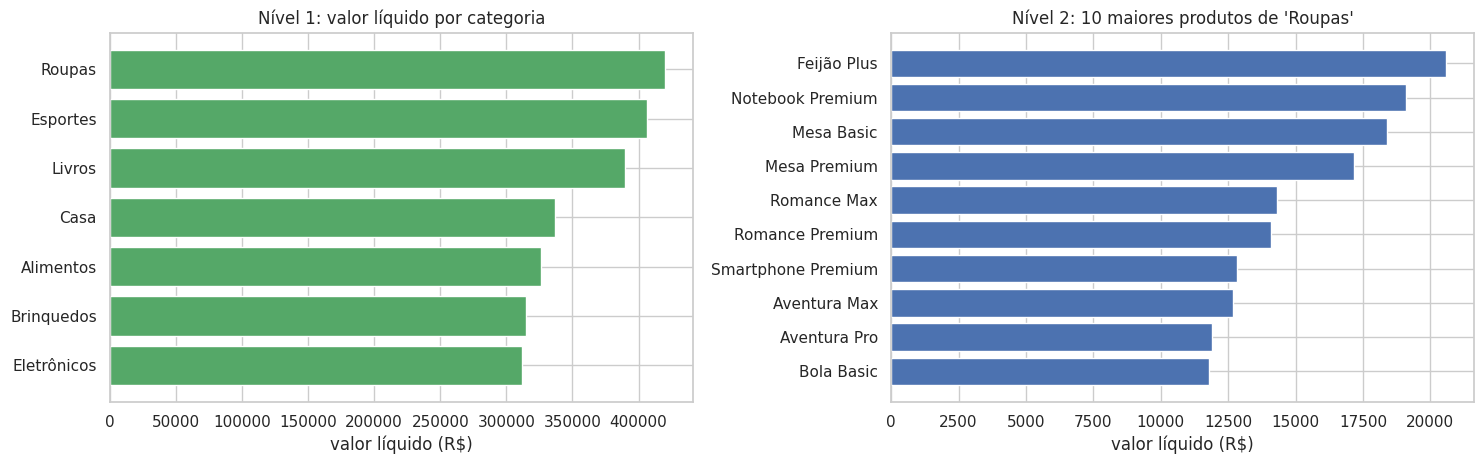

'Roupas' lidera com R$ 420,051.47 (16.8% do total).
Dentro dela, o maior produto é 'Feijão Plus' (R$ 20,589.79).

Drill-down no tempo: ano 2026 -> trimestre -> mês


valor_liquido
trimestre nome_mes                
1         fevereiro     154,155.07
          janeiro       176,518.97
          março         233,310.87
2         abril         207,756.84
          junho         203,306.99
          maio          200,754.35
3         agosto        174,181.47
          julho         267,439.28
          setembro      221,789.86
4         outubro        52,738.83

In [5]:
por_categoria = cubo.groupby("categoria")["valor_liquido"].sum().sort_values(ascending=False)
top_categoria = por_categoria.index[0]

produtos_top = (
    cubo[cubo["categoria"] == top_categoria]
    .groupby("produto")["valor_liquido"].sum()
    .sort_values(ascending=False)
)

fig, eixos = plt.subplots(1, 2, figsize=(15, 4.8))
eixos[0].barh(por_categoria.index[::-1], por_categoria.values[::-1], color="#55A868")
eixos[0].set(title="Nível 1: valor líquido por categoria", xlabel="valor líquido (R$)")
top10 = produtos_top.head(10)
eixos[1].barh(top10.index[::-1], top10.values[::-1], color="#4C72B0")
eixos[1].set(title=f"Nível 2: 10 maiores produtos de '{top_categoria}'", xlabel="valor líquido (R$)")
plt.tight_layout()
plt.show()

print(f"'{top_categoria}' lidera com R$ {por_categoria.iloc[0]:,.2f} ({100 * por_categoria.iloc[0] / por_categoria.sum():.1f}% do total).")
print(f"Dentro dela, o maior produto é '{produtos_top.index[0]}' (R$ {produtos_top.iloc[0]:,.2f}).")

# drill-down no tempo: ano -> trimestre -> mês do melhor ano
melhor_ano = por_ano.idxmax()
detalhe = (
    cubo[cubo["ano"] == melhor_ano]
    .groupby(["trimestre", "nome_mes"])["valor_liquido"].sum()
    .to_frame("valor_liquido")
)
print(f"\nDrill-down no tempo: ano {melhor_ano} -> trimestre -> mês")
display(detalhe)

## 5. Slice e Dice

**Slice** fixa uma dimensão. **Dice** corta o cubo em várias dimensões ao mesmo tempo.

In [6]:
# ---- SLICE: fixa a dimensão tempo em um único mês (o de maior venda) ----
mes_slice = por_mes.idxmax()
fatia = cubo[cubo["ano_mes"] == mes_slice]
slice_categoria = fatia.groupby("categoria")["valor_liquido"].agg(["sum", "count"]).sort_values("sum", ascending=False)
slice_categoria.columns = ["valor_liquido", "compras"]

print(f"SLICE: apenas {mes_slice} ({len(fatia)} compras, de {n_fato})")
display(slice_categoria)

SLICE: apenas 2026-07 (112 compras, de 1184)


,valor_liquido,compras
categoria,,
Roupas,"52,889.67",23
Livros,"41,325.90",19
Alimentos,"41,290.01",17
Brinquedos,"36,793.57",17
Casa,"32,728.88",12
Esportes,"32,393.58",12
Eletrônicos,"30,017.67",12


DICE: status pago/entregue, 2026-01-01 a 2026-06-30, categorias ['Roupas', 'Esportes', 'Livros']
      103 compras, de 1184



,T1,T2
categoria,,
Esportes,"40,076.88","35,174.21"
Livros,"37,770.91","32,034.37"
Roupas,"20,860.30","39,751.94"


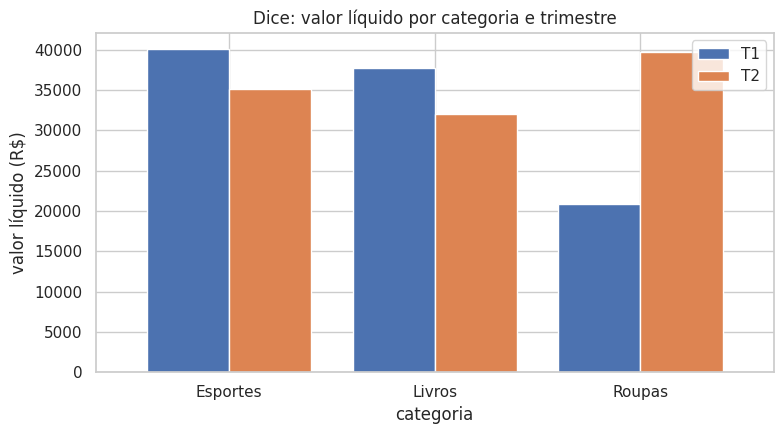

Nesse recorte, a melhor combinação é ('Esportes', 'T1') (R$ 40,076.88).


In [7]:
# ---- DICE: várias dimensões ao mesmo tempo ----
#   status    = vendas concluídas (pago ou entregue)
#   tempo     = 1º semestre do ano com mais compras
#   categoria = as 3 maiores categorias
ano_ref = int(cubo["ano"].value_counts().idxmax())
inicio, fim = pd.Timestamp(f"{ano_ref}-01-01"), pd.Timestamp(f"{ano_ref}-06-30")
top3 = list(por_categoria.index[:3])

dado = cubo[
    cubo["status"].isin(["pago", "entregue"])
    & cubo["data"].between(inicio, fim + pd.Timedelta(days=1) - pd.Timedelta(microseconds=1))
    & cubo["categoria"].isin(top3)
]

print(f"DICE: status pago/entregue, {inicio.date()} a {fim.date()}, categorias {top3}")
print(f"      {len(dado)} compras, de {n_fato}\n")

dice_tabela = dado.pivot_table(index="categoria", columns="trimestre", values="valor_liquido", aggfunc="sum", fill_value=0)
dice_tabela.columns = [f"T{c}" for c in dice_tabela.columns]
display(dice_tabela)

if len(dado):
    ax = dice_tabela.plot.bar(figsize=(8, 4.5), width=0.8)
    ax.set(title="Dice: valor líquido por categoria e trimestre", xlabel="categoria", ylabel="valor líquido (R$)")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    plt.show()
    print(f"Nesse recorte, a melhor combinação é {dice_tabela.stack().idxmax()} (R$ {dice_tabela.stack().max():,.2f}).")
else:
    print("O recorte do dice não retornou compras. Ajuste os filtros.")

## 6. Pivot: categoria × faixa etária

Cruza duas dimensões em uma tabela. O mapa de calor mostra onde o valor se concentra.

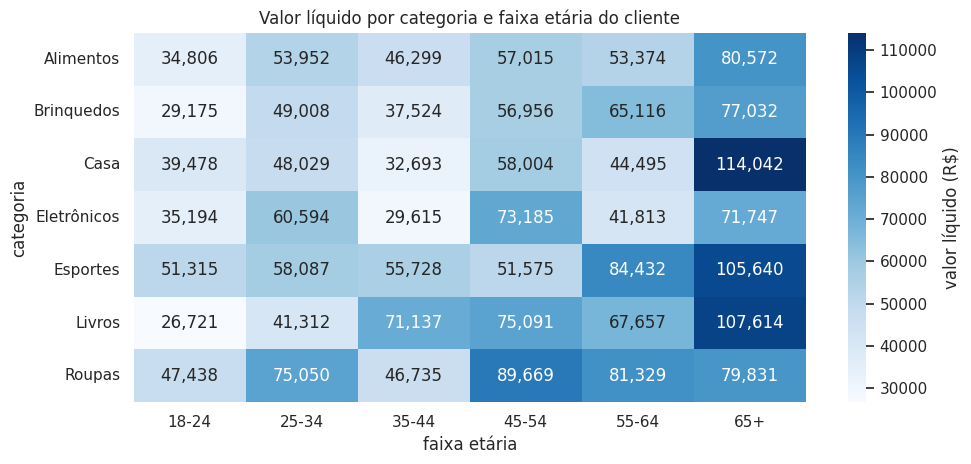

Maior concentração: Casa para clientes de 65+ anos (R$ 114,042.23).
Faixa etária que mais gera valor: 65+ (25.4% do total).


In [8]:
ordem_faixas = [f for f in ["18-24", "25-34", "35-44", "45-54", "55-64", "65+", "Não informada"] if f in set(cubo["faixa_etaria"])]
pivo = cubo.pivot_table(index="categoria", columns="faixa_etaria", values="valor_liquido", aggfunc="sum", fill_value=0)[ordem_faixas]

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(pivo, annot=True, fmt=",.0f", cmap="Blues", cbar_kws={"label": "valor líquido (R$)"}, ax=ax)
ax.set(title="Valor líquido por categoria e faixa etária do cliente", xlabel="faixa etária", ylabel="categoria")
plt.tight_layout()
plt.show()

par = pivo.stack().idxmax()
print(f"Maior concentração: {par[0]} para clientes de {par[1]} anos (R$ {pivo.stack().max():,.2f}).")
por_faixa = pivo.sum()
print(f"Faixa etária que mais gera valor: {por_faixa.idxmax()} ({100 * por_faixa.max() / por_faixa.sum():.1f}% do total).")

## 7. Cancelamentos

Parte do valor das compras não vira venda de fato. A taxa de cancelamento por categoria mostra onde isso pesa mais.

,compras,canceladas,valor_cancelado,taxa_cancelamento_%
categoria,,,,
Brinquedos,156,37,"78,425.49",23.70
Casa,158,37,"75,117.41",23.40
Roupas,197,45,"108,620.83",22.80
Eletrônicos,148,31,"67,884.09",20.90
Livros,183,35,"85,445.15",19.10
Alimentos,155,28,"59,767.96",18.10
Esportes,187,33,"82,758.57",17.60


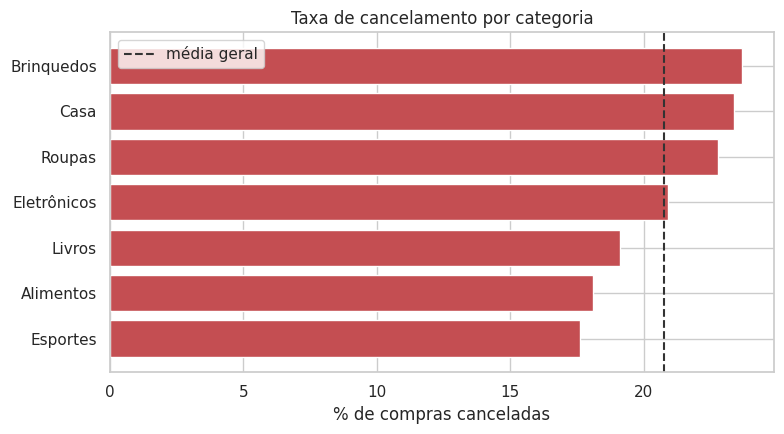

Média geral de cancelamento: 20.8% das compras (R$ 558,019.50, 22.3% do valor líquido).
Maior taxa: Brinquedos (23.7%). Menor: Esportes (17.6%).


In [9]:
cancel = cubo.assign(cancelado=cubo["status"].eq("cancelado")).groupby("categoria").agg(
    compras=("id_compra", "count"),
    canceladas=("cancelado", "sum"),
    valor_cancelado=("valor_liquido", lambda s: s[cubo.loc[s.index, "status"].eq("cancelado")].sum()),
)
cancel["taxa_cancelamento_%"] = (100 * cancel["canceladas"] / cancel["compras"]).round(1)
cancel = cancel.sort_values("taxa_cancelamento_%", ascending=False)
display(cancel)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(cancel.index[::-1], cancel["taxa_cancelamento_%"][::-1], color="#C44E52")
ax.axvline(100 * cubo["status"].eq("cancelado").mean(), color="#333333", linestyle="--", label="média geral")
ax.set(title="Taxa de cancelamento por categoria", xlabel="% de compras canceladas")
ax.legend()
plt.tight_layout()
plt.show()

media = 100 * cubo["status"].eq("cancelado").mean()
valor_canc = cubo.loc[cubo["status"].eq("cancelado"), "valor_liquido"].sum()
print(f"Média geral de cancelamento: {media:.1f}% das compras (R$ {valor_canc:,.2f}, {100 * valor_canc / cubo['valor_liquido'].sum():.1f}% do valor líquido).")
print(f"Maior taxa: {cancel.index[0]} ({cancel['taxa_cancelamento_%'].iloc[0]}%). Menor: {cancel.index[-1]} ({cancel['taxa_cancelamento_%'].iloc[-1]}%).")

## 8. Salvar os resultados

Grava as tabelas de resultado em CSV. Elas servem de evidência da etapa e podem ser versionadas no repositório.

In [10]:
if SALVAR_NO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        SAIDA = f"{DRIVE_PASTA}/olap"
    except ImportError:
        print("Fora do Colab: salvando na pasta local", SAIDA)
os.makedirs(SAIDA, exist_ok=True)

resultados = {
    "olap_rollup_mes": por_mes.rename("valor_liquido").reset_index(),
    "olap_rollup_trimestre": por_trimestre.rename("valor_liquido").rename_axis("trimestre").reset_index(),
    "olap_drilldown_categoria": por_categoria.rename("valor_liquido").reset_index(),
    "olap_drilldown_produto": produtos_top.rename("valor_liquido").reset_index(),
    "olap_slice_mes": slice_categoria.reset_index(),
    "olap_dice": dice_tabela.reset_index(),
    "olap_pivot_categoria_faixa": pivo.reset_index(),
    "olap_cancelamento": cancel.reset_index(),
}
for nome, df in resultados.items():
    df.to_csv(f"{SAIDA}/{nome}_{LOTE}.csv", index=False)
    print(f"{SAIDA}/{nome}_{LOTE}.csv  {len(df):>4} linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/gardenia/olap/olap_rollup_mes_1.csv    13 linhas
/content/drive/MyDrive/gardenia/olap/olap_rollup_trimestre_1.csv     5 linhas
/content/drive/MyDrive/gardenia/olap/olap_drilldown_categoria_1.csv     7 linhas
/content/drive/MyDrive/gardenia/olap/olap_drilldown_produto_1.csv    60 linhas
/content/drive/MyDrive/gardenia/olap/olap_slice_mes_1.csv     7 linhas
/content/drive/MyDrive/gardenia/olap/olap_dice_1.csv     3 linhas
/content/drive/MyDrive/gardenia/olap/olap_pivot_categoria_faixa_1.csv     7 linhas
/content/drive/MyDrive/gardenia/olap/olap_cancelamento_1.csv     7 linhas


## Próximos passos

**Etapa 6: Data Mining (K-Means / RFM).** Ler o DW, calcular recência, frequência e valor por cliente e segmentar os clientes.

Checklist antes do commit:

- [ ] os notebooks 03 e 04 foram rodados antes, com o mesmo `LOTE`;
- [ ] as cinco operações (roll-up, drill-down, slice, dice, pivot) aparecem com tabela e gráfico;
- [ ] cada gráfico tem título, eixos rotulados e uma frase de interpretação;
- [ ] os avisos sobre o primeiro e o último mês incompletos aparecem quando for o caso.